In [ ]:
!cp /kaggle/input/datane123/detr_resume_checkpoint.pth /kaggle/working/
!cp /kaggle/input/datane123/training_log.json /kaggle/working/
!cp -r /kaggle/input/datane123/best_model /kaggle/working/

In [3]:
# 1. CÀI ĐẶT THƯ VIỆN
!pip install -q torch torchvision torchaudio pycocotools matplotlib tqdm
!pip install -q torchmetrics transformers seaborn timm scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 116.2 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 91.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 42.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 3.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 4.0 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 14.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 9.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 86.4 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed

In [4]:
import os
import json
import time
import random
import numpy as np
import cv2
import torch
import torch.nn as nn
import albumentations as A
import warnings
from PIL import Image
from tqdm.notebook import tqdm
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from transformers import DeformableDetrImageProcessor, DeformableDetrForObjectDetection
from torchmetrics.detection import MeanAveragePrecision

# Tắt cảnh báo
warnings.filterwarnings("ignore")
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

2025-11-27 09:33:37.616657: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764236017.798600      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764236017.846300      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

In [5]:
# ================= 1. CẬP NHẬT LẠI CONFIG (BỊ THIẾU DÒNG THỜI GIAN) =================
CONFIG = {
    'MODEL_ID': "SenseTime/deformable-detr", 
    'IMG_SIZE': 480,         
    'EPOCHS': 50,            
    'BATCH_SIZE': 4,         
    'ACCUMULATION_STEPS': 4, 
    'LR': 1e-4,
    'LR_BACKBONE': 1e-5,
    'WEIGHT_DECAY': 1e-4,
    
    # --- DÒNG BỊ THIẾU GÂY RA LỖI KEY ERROR ---
    'MAX_TIME_SEC': 11.5 * 3600, # 11.5 tiếng (đổi ra giây)
    # ------------------------------------------

    "TRAIN_IMG_DIR": "/kaggle/input/traffic-object/coco_split/coco_split/train",
    "TRAIN_ANN_FILE": "/kaggle/input/traffic-object/coco_split/coco_split/annotations/instances_train.json",
    "VAL_IMG_DIR":   "/kaggle/input/traffic-object/coco_split/coco_split/val",
    "VAL_ANN_FILE":  "/kaggle/input/traffic-object/coco_split/coco_split/annotations/instances_val.json",
    
    "SAVE_DIR": "/kaggle/working/",
    "CHECKPOINT_FILE": "/kaggle/working/detr_resume_checkpoint.pth",
    "BEST_MODEL_DIR": "/kaggle/working/best_model/"
}

In [6]:
processor = DeformableDetrImageProcessor.from_pretrained(CONFIG['MODEL_ID'], do_resize=False, do_pad=False)

class CocoDataset(Dataset):
    def __init__(self, root, ann_file, processor, train=True):
        self.root = root
        self.processor = processor
        self.train = train
        with open(ann_file) as f: self.coco = json.load(f)
        self.images = {img['id']: img for img in self.coco['images']}
        self.annotations = {img_id: [] for img_id in self.images.keys()}
        for ann in self.coco['annotations']: self.annotations[ann['image_id']].append(ann)
        self.ids = list(self.images.keys())
        
        # Transform với size 480
        self.transform = A.Compose([
            A.Resize(CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"]),
            A.HorizontalFlip(p=0.5) if train else A.NoOp(),
            A.RandomBrightnessContrast(p=0.2) if train else A.NoOp(),
            A.ColorJitter(p=0.3) if train else A.NoOp(),
        ], bbox_params=A.BboxParams(format='coco', label_fields=['category_ids'], min_visibility=0.1))

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        img_path = os.path.join(self.root, self.images[img_id]['file_name'])
        image = cv2.imread(img_path)
        if image is None: image = np.zeros((CONFIG['IMG_SIZE'], CONFIG['IMG_SIZE'], 3), dtype=np.uint8)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h_img, w_img = image.shape[:2]
        
        anns = self.annotations[img_id]
        boxes, labels, ids, areas, iscrowd = [], [], [], [], []
        for ann in anns:
            x, y, w, h = ann['bbox']
            x_min, y_min = max(0, x), max(0, y)
            x_max, y_max = min(w_img, x+w), min(h_img, y+h)
            nw, nh = x_max - x_min, y_max - y_min
            if nw > 1 and nh > 1:
                boxes.append([x_min, y_min, nw, nh])
                labels.append(ann['category_id'])
                ids.append(ann['id'])
                areas.append(ann['area'])
                iscrowd.append(ann.get('iscrowd', 0))
                
        if len(boxes) > 0:
            try:
                t = self.transform(image=image, bboxes=boxes, category_ids=labels)
                image, boxes, labels = t['image'], t['bboxes'], t['category_ids']
            except:
                image = A.Resize(CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"])(image=image)['image']
                boxes, labels = [], []
        else:
            image = A.Resize(CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"])(image=image)['image']

        target = {'image_id': img_id, 'annotations': []}
        for i in range(len(boxes)):
            target['annotations'].append({'id': ids[i] if i<len(ids) else 0, 'image_id': img_id, 'category_id': labels[i], 'bbox': boxes[i], 'area': areas[i] if i<len(areas) else 0, 'iscrowd': 0})
            
        enc = self.processor(images=Image.fromarray(image), annotations=target, return_tensors="pt")
        mask = enc['pixel_mask'].squeeze() if 'pixel_mask' in enc else torch.ones((image.shape[0], image.shape[1]), dtype=torch.long)
        return {'pixel_values': enc['pixel_values'].squeeze(), 'pixel_mask': mask, 'labels': enc['labels'][0]}

    def __len__(self): return len(self.ids)

def collate_fn(batch):
    enc = processor.pad([x['pixel_values'] for x in batch], return_tensors="pt")
    return {'pixel_values': enc['pixel_values'], 'pixel_mask': enc['pixel_mask'], 'labels': [x['labels'] for x in batch]}

preprocessor_config.json:   0%|          | 0.00/305 [00:00<?, ?B/s]

In [7]:
print("Loading Datasets...")
train_ds = CocoDataset(CONFIG["TRAIN_IMG_DIR"], CONFIG["TRAIN_ANN_FILE"], processor, True)
val_ds   = CocoDataset(CONFIG["VAL_IMG_DIR"], CONFIG["VAL_ANN_FILE"], processor, False)

train_loader = DataLoader(train_ds, CONFIG["BATCH_SIZE"], shuffle=True, collate_fn=collate_fn, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=2)
val_loader   = DataLoader(val_ds, CONFIG["BATCH_SIZE"], shuffle=False, collate_fn=collate_fn, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=2)

# Tự động lấy số class từ dữ liệu
num_labels = len({cat['id'] for cat in train_ds.coco['categories']})
id2label = {cat['id']: cat['name'] for cat in train_ds.coco['categories']}
label2id = {v: k for k, v in id2label.items()}

model = DeformableDetrForObjectDetection.from_pretrained(CONFIG['MODEL_ID'], num_labels=num_labels, id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True)
model.to(device)

print(f"Ready: {len(train_ds)} train images, {len(val_ds)} val images.")

Loading Datasets...


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/161M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Some weights of the model checkpoint at SenseTime/deformable-detr were not used when initializing DeformableDetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DeformableDetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DeformableDetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DeformableDetrForObjectDetection wer

Ready: 22257 train images, 4766 val images.


In [8]:
param_dicts = [
    {"params": [p for n, p in model.named_parameters() if "backbone" not in n and p.requires_grad]},
    { "params": [p for n, p in model.named_parameters() if "backbone" in n and p.requires_grad], "lr": CONFIG["LR_BACKBONE"] }
]
optimizer = AdamW(param_dicts, lr=CONFIG["LR"], weight_decay=CONFIG["WEIGHT_DECAY"])
scheduler = CosineAnnealingLR(optimizer, T_max=50) # <--- Scheduler tính cho 50 epochs
scaler = torch.amp.GradScaler("cuda")
metric = MeanAveragePrecision(iou_type="bbox").to(device)

# ================= 4. LOGIC RESUME THÔNG MINH =================
start_epoch = 0
best_map = 0.0

# Nếu có file checkpoint trong folder working (Lần chạy trước lưu lại)
if os.path.exists(CONFIG["CHECKPOINT_FILE"]):
    print(f"PHÁT HIỆN CHECKPOINT: {CONFIG['CHECKPOINT_FILE']}")
    ckpt = torch.load(CONFIG["CHECKPOINT_FILE"], map_location=device)
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['opt'])
    scaler.load_state_dict(ckpt['scaler'])
    scheduler.load_state_dict(ckpt['sched'])
    start_epoch = ckpt['epoch'] + 1
    best_map = ckpt.get('best_map', 0.0)
    print(f"RESUME TỪ EPOCH {start_epoch+1}. Best mAP hiện tại: {best_map:.4f}")
else:
    print("KHÔNG TÌM THẤY CHECKPOINT. TRAINING TỪ ĐẦU (EPOCH 1).")

KHÔNG TÌM THẤY CHECKPOINT. TRAINING TỪ ĐẦU (EPOCH 1).


In [10]:
# --- KHỞI TẠO BIẾN LƯU LOG ---
history_file = "training_log.json"
history = {"train_loss": [], "val_map": [], "val_ar": [], "f1": []}
start_epoch = 0
best_map = 0.0

# Nếu chạy tiếp (Resume), thử load checkpoint
if os.path.exists(CONFIG["CHECKPOINT_FILE"]):
    print("Resume từ checkpoint...")
    ckpt = torch.load(CONFIG["CHECKPOINT_FILE"], map_location="cpu")
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["opt"])
    scaler.load_state_dict(ckpt["scaler"])
    scheduler.load_state_dict(ckpt["sched"])

    start_epoch = ckpt["epoch"] + 1
    best_map = ckpt.get("best_map", 0.0)

    if os.path.exists(history_file):
        try:
            with open(history_file, 'r') as f:
                history = json.load(f)
            print(f"Đã load training_log.json ({len(history['train_loss'])} epochs)")
        except:
            print("Không đọc được file log cũ, tạo log mới.")

    print(f"Tiếp tục từ epoch {start_epoch}, best mAP={best_map:.4f}")
else:
    print("Training mới từ đầu!")

session_start_time = time.time()
print(f"\nBẮT ĐẦU CHẠY! MỤC TIÊU: {CONFIG['EPOCHS']} EPOCHS.")

# ------------------ TRAINING LOOP ------------------
for epoch in range(start_epoch, CONFIG["EPOCHS"]):

    # --- GIỚI HẠN THỜI GIAN ---
    elapsed = time.time() - session_start_time
    if elapsed > CONFIG['MAX_TIME_SEC']:
        print(f"\nHẾT GIỜ ({elapsed/3600:.1f}h). Lưu checkpoint và dừng!")
        break

    # TRAIN
    model.train()
    epoch_loss = 0
    optimizer.zero_grad()
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{CONFIG['EPOCHS']}")

    for i, batch in enumerate(pbar):
        pixel_values = batch['pixel_values'].to(device)
        pixel_mask = batch['pixel_mask'].to(device)
        labels = [{k: v.to(device) for k, v in t.items()} for t in batch['labels']]

        with torch.amp.autocast("cuda"):
            loss = model(pixel_values=pixel_values, pixel_mask=pixel_mask, labels=labels).loss
            loss = loss / CONFIG['ACCUMULATION_STEPS']

        scaler.scale(loss).backward()

        if (i + 1) % CONFIG['ACCUMULATION_STEPS'] == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        current_loss = loss.item() * CONFIG['ACCUMULATION_STEPS']
        epoch_loss += current_loss
        pbar.set_postfix(loss=current_loss)

    scheduler.step()
    avg_loss = epoch_loss / len(train_loader)

    # EVAL
    print(f"Evaluating Epoch {epoch+1}...")
    model.eval()
    metric.reset()

    with torch.no_grad():
        for batch in tqdm(val_loader, leave=False):
            pixel_values = batch['pixel_values'].to(device)
            pixel_mask = batch['pixel_mask'].to(device)
            labels = [{k: v.to(device) for k, v in t.items()} for t in batch['labels']]

            outputs = model(pixel_values=pixel_values, pixel_mask=pixel_mask)
            sizes = torch.stack([t["orig_size"] for t in labels], 0)
            results = processor.post_process_object_detection(outputs, target_sizes=sizes, threshold=0.01)

            preds = [{"boxes": r["boxes"], "scores": r["scores"], "labels": r["labels"]} for r in results]

            targets = []
            for j, l in enumerate(labels):
                h, w = sizes[j]
                boxes = l['boxes'] * torch.tensor([w, h, w, h], device=device)
                cx, cy, ww, hh = boxes.unbind(-1)
                xyxy = torch.stack([
                    cx - 0.5 * ww, cy - 0.5 * hh,
                    cx + 0.5 * ww, cy + 0.5 * hh
                ], -1)
                targets.append({"boxes": xyxy, "labels": l["class_labels"]})

            metric.update(preds, targets)

    # METRIC
    res = metric.compute()
    
    # Lấy các chỉ số cơ bản
    mAP = res.get("map", torch.tensor(0.0)).item()
    mAP50 = res.get("map_50", torch.tensor(0.0)).item()
    mAP75 = res.get("map_75", torch.tensor(0.0)).item()
    
    # Lấy các chỉ số theo kích thước (Small, Medium, Large)
    mAP_small = res.get("map_small", torch.tensor(0.0)).item()
    mAP_medium = res.get("map_medium", torch.tensor(0.0)).item()
    mAP_large = res.get("map_large", torch.tensor(0.0)).item()
    
    # Lấy Recall (AR)
    AR1 = res.get("mar_1", torch.tensor(0.0)).item()
    AR10 = res.get("mar_10", torch.tensor(0.0)).item()
    AR100 = res.get("mar_100", torch.tensor(0.0)).item() # Đây thường được dùng làm Recall tổng quát

    # --- TÍNH TOÁN PRECISION, RECALL, F1 CHO BẢNG ---
    # Trong Object Detection, không có 1 số Precision duy nhất nếu không chọn ngưỡng score.
    # Tuy nhiên, để khớp với bảng, ta thường dùng:
    # Precision ≈ mAP (hoặc mAP50 tùy định nghĩa, ở đây dùng mAP tổng quát)
    # Recall    ≈ AR100 (Max Recall)
    
    val_precision = mAP 
    val_recall = AR100
    
    # Tính F1 Score (Harmonic mean giữa Precision và Recall)
    f1 = 0
    if (val_precision + val_recall) > 0:
        f1 = 2 * (val_precision * val_recall) / (val_precision + val_recall)

    # LOG - Cập nhật dictionary history đầy đủ các cột
    history["train_loss"].append(avg_loss)
    history["val_map"].append(mAP)
    history.setdefault("val_map50", []).append(mAP50)
    history.setdefault("val_map75", []).append(mAP75)
    
    # Thêm các cột mới vào log
    history.setdefault("val_ap_small", []).append(mAP_small)
    history.setdefault("val_ap_medium", []).append(mAP_medium)
    history.setdefault("val_ap_large", []).append(mAP_large)
    history.setdefault("val_precision", []).append(val_precision)
    history.setdefault("val_recall", []).append(val_recall)
    history["f1"].append(f1) # Đã có sẵn trong code cũ nhưng giờ tính chính xác hơn

    # Lưu file JSON
    with open(history_file, 'w') as f:
        json.dump(history, f)

    # PRINT - In ra màn hình giống format bảng trong ảnh
    print(f"\nEpoch {epoch+1} Results:")
    print("-" * 110)
    print(f"{'mAP':<10} {'AP50':<10} {'AP75':<10} {'Small':<10} {'Medium':<10} {'Large':<10} {'Prec':<10} {'Recall':<10} {'F1':<10}")
    print(f"{mAP:<10.4f} {mAP50:<10.4f} {mAP75:<10.4f} {mAP_small:<10.4f} {mAP_medium:<10.4f} {mAP_large:<10.4f} {val_precision:<10.4f} {val_recall:<10.4f} {f1:<10.4f}")
    print("-" * 110)
    print(f"Best mAP: {best_map:.4f}")

    # SAVE CHECKPOINT
    state = {
        'epoch': epoch,
        'model': model.state_dict(),
        'opt': optimizer.state_dict(),
        'scaler': scaler.state_dict(),
        'sched': scheduler.state_dict(),
        'best_map': best_map if mAP <= best_map else mAP,
    }
    torch.save(state, CONFIG["CHECKPOINT_FILE"])
    print(f"Đã lưu Checkpoint: {CONFIG['CHECKPOINT_FILE']}")

    # BEST MODEL
    if mAP > best_map:
        best_map = mAP
        model.save_pretrained(CONFIG["BEST_MODEL_DIR"])
        processor.save_pretrained(CONFIG["BEST_MODEL_DIR"])
        print("NEW BEST MODEL SAVED!")
# ------------------ END ------------------
print("\nKẾT THÚC PHIÊN CHẠY.")
if epoch < CONFIG['EPOCHS'] - 1:
    print("CHƯA XONG, tải checkpoint về và train tiếp!")
else:
    print("HOÀN THÀNH toàn bộ EPOCHS!")


Training mới từ đầu!

BẮT ĐẦU CHẠY! MỤC TIÊU: 50 EPOCHS.


Epoch 1/50:   0%|          | 0/5565 [00:00<?, ?it/s]

RuntimeError: DataLoader worker (pid(s) 172, 173, 174, 175) exited unexpectedly

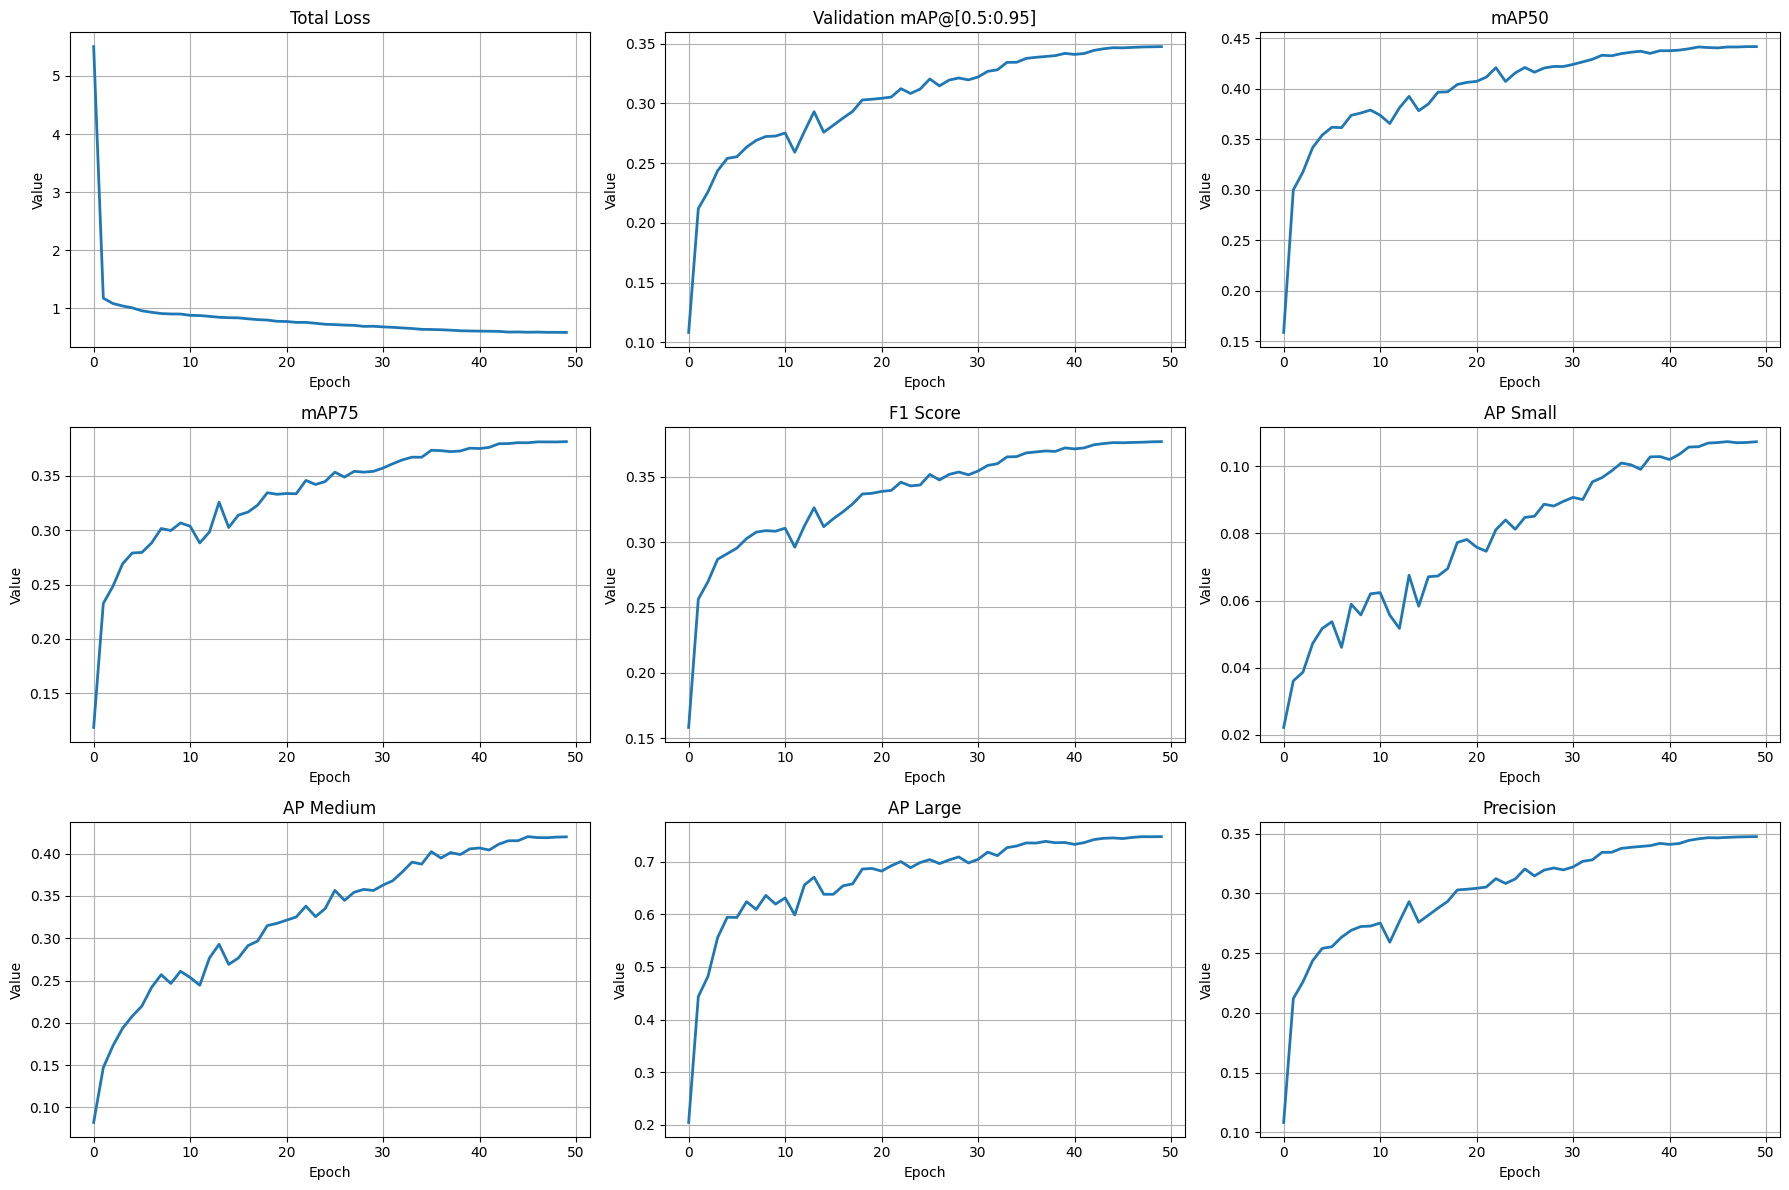

In [ ]:
import json
import matplotlib.pyplot as plt
import matplotlib
import os

# --- FIX FONT ---
matplotlib.rcParams.update(matplotlib.rcParamsDefault)

# =====================================================
# 1) Đọc file JSON log
# =====================================================
log_file = "/kaggle/input/datane123/training_log.json"
with open(log_file, "r") as f:
    history = json.load(f)

# =====================================================
# 2) Tạo figure với nhiều subplot
# =====================================================
metrics = [
    ("train_loss", "Total Loss"),
    ("val_map", "Validation mAP per Epoch"),
    ("val_map50", "mAP50"),
    ("val_map75", "mAP75"),
    ("f1", "F1 Score"),
    ("val_ap_small", "AP Small"),
    ("val_ap_medium", "AP Medium"),
    ("val_ap_large", "AP Large"),
    ("val_precision", "Precision")
]

# Số hàng và cột cho subplot (thay đổi tuỳ số metric)
n_rows = 3
n_cols = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 12))
axes = axes.flatten()

for i, (key, title) in enumerate(metrics):
    if key in history:
        axes[i].plot(history[key], linewidth=2)
        axes[i].set_title(title)
        axes[i].set_xlabel("Epoch")
        axes[i].set_ylabel("Value")
        axes[i].grid(True)
    else:
        axes[i].text(0.5, 0.5, f"{key} not found", ha='center', va='center')
        axes[i].set_axis_off()

plt.tight_layout()
plt.show()

# --- Lưu hình ---
os.makedirs("charts", exist_ok=True)
fig.savefig("charts/all_metrics.png", dpi=200)


In [ ]:
import json
import matplotlib.pyplot as plt
import matplotlib
import os

matplotlib.rcParams.update(matplotlib.rcParamsDefault)

log_file = "/kaggle/input/datane123/training_log.json"
with open(log_file, "r") as f:
    history = json.load(f)

metrics = [
    ("train_loss", "Training Loss Convergence"),
    ("val_map", "Validation mAP per Epoch"),
    ("val_map50", "mAP50"),
    ("val_map75", "mAP75"),
    ("f1", "F1 Score"),
    ("val_ap_small", "AP Small"),
    ("val_ap_medium", "AP Medium"),
    ("val_ap_large", "AP Large"),
    ("val_precision", "Precision")
]

os.makedirs("charts", exist_ok=True)

# ==============================
# STYLE GIỐNG HÌNH MẪU
# ==============================
for key, title in metrics:
    if key not in history:
        continue

    y = history[key]
    x = list(range(len(y)))

    plt.figure(figsize=(12, 8))

    # Fill dưới đường
    plt.fill_between(x, y, alpha=0.20)

    # Đường line + marker
    plt.plot(x, y, marker='o', linewidth=3)

    # Title lớn kiểu bold
    plt.title(title, fontsize=22, fontweight="bold")

    # Label trục
    plt.xlabel("Epoch", fontsize=16, fontweight="bold")
    plt.ylabel("Value", fontsize=16, fontweight="bold")

    # Lưới dashed nhẹ
    plt.grid(True, linestyle='--', alpha=0.5)

    # Viền trục đậm giống hình bạn đưa
    for spine in ["left", "bottom"]:
        plt.gca().spines[spine].set_linewidth(3)
        plt.gca().spines[spine].set_color("black")

    # Tắt viền trên + phải
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)

    # Legend
    plt.legend([title], fontsize=14)

    plt.tight_layout()
    plt.ylim(0, 1)

    # Save file từng hình
    plt.savefig(f"charts/{key}.png", dpi=200)
    plt.close()

print("Đã xuất tất cả hình với style giống mẫu!")


Đã xuất tất cả hình với style giống mẫu!


✔ Loading from BEST_MODEL_DIR


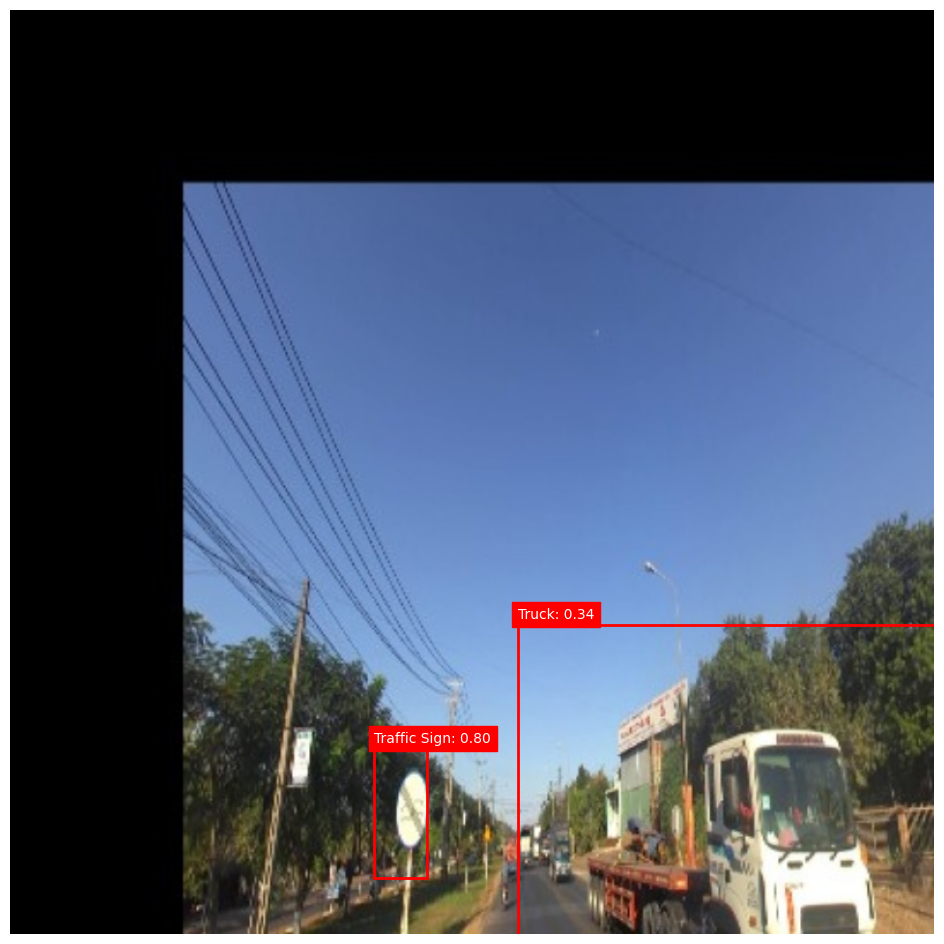

In [29]:
import os, json, torch, numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from transformers import DeformableDetrImageProcessor, DeformableDetrForObjectDetection

BEST_MODEL_DIR = "/kaggle/working/best_model"
CHECKPOINT_FILE = "/kaggle/working/detr_resume_checkpoint.pth"
FALLBACK_MODEL = "SenseTime/deformable-detr"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_model_and_processor():
    if os.path.isdir(BEST_MODEL_DIR):
        print("✔ Loading from BEST_MODEL_DIR")
        processor = DeformableDetrImageProcessor.from_pretrained(BEST_MODEL_DIR)
        model = DeformableDetrForObjectDetection.from_pretrained(BEST_MODEL_DIR).to(DEVICE)
        return processor, model

    if os.path.exists(CHECKPOINT_FILE):
        print("✔ Loading checkpoint fallback")
        processor = DeformableDetrImageProcessor.from_pretrained(FALLBACK_MODEL)
        model = DeformableDetrForObjectDetection.from_pretrained(FALLBACK_MODEL, ignore_mismatched_sizes=True)
        ckpt = torch.load(CHECKPOINT_FILE, map_location="cpu")
        model.load_state_dict(ckpt['model'], strict=False)
        return processor, model.to(DEVICE)

    print("⚠ No saved model found → using base model")
    processor = DeformableDetrImageProcessor.from_pretrained(FALLBACK_MODEL)
    model = DeformableDetrForObjectDetection.from_pretrained(FALLBACK_MODEL).to(DEVICE)
    return processor, model


processor, model = load_model_and_processor()

id2label = {int(k): v for k, v in model.config.id2label.items()}


def predict_and_visualize(image_path, threshold=0.3):
    image = Image.open(image_path).convert("RGB")
    inputs = processor(images=image, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)

    target_sizes = torch.tensor([image.size[::-1]], device=DEVICE)
    results = processor.post_process_object_detection(outputs, target_sizes=target_sizes, threshold=threshold)[0]

    boxes, scores, labels = results["boxes"], results["scores"], results["labels"]

    fig, ax = plt.subplots(1, figsize=(12, 12))
    ax.imshow(image)

    for box, score, lab in zip(boxes, scores, labels):
        x1, y1, x2, y2 = box.cpu().numpy()
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                 linewidth=2, edgecolor="red", facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, y1-5, f"{id2label[int(lab)]}: {score:.2f}",
                color="white", backgroundcolor="red", fontsize=10)

    plt.axis("off")
    plt.show()


# Test thử ảnh
test_image = "/kaggle/input/traffic-object/coco_split/coco_split/test/3716_aug1.jpg"  # đổi đường dẫn theo ảnh của bạn
predict_and_visualize(test_image)


⚠ No saved model found → using base model


Some weights of the model checkpoint at SenseTime/deformable-detr were not used when initializing DeformableDetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DeformableDetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DeformableDetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


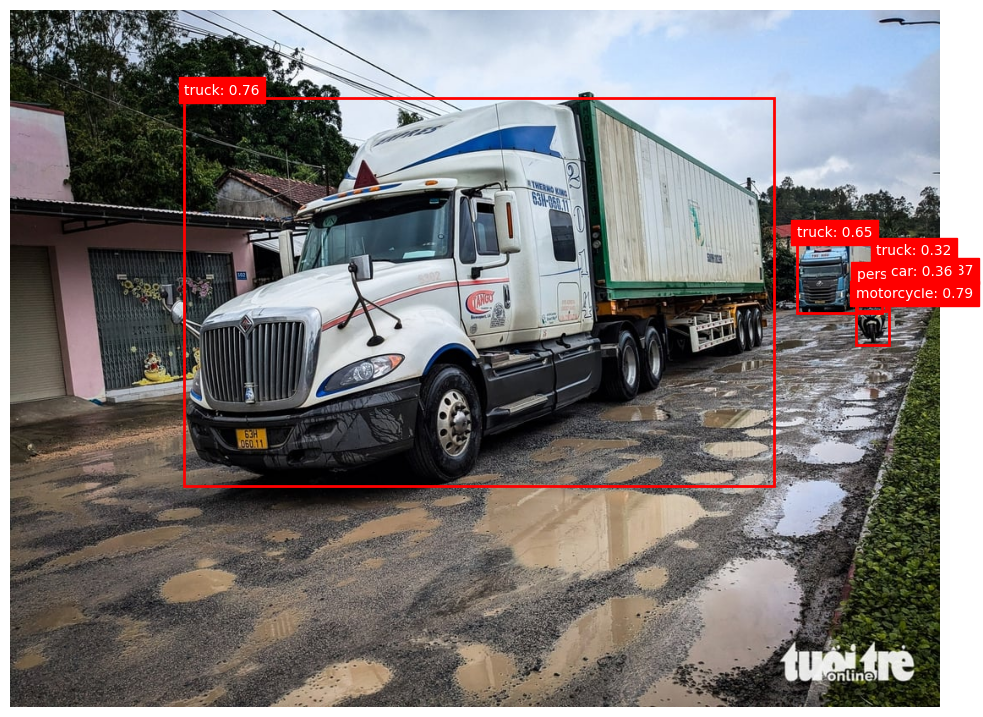

In [5]:
import os, json, torch, numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from transformers import DeformableDetrImageProcessor, DeformableDetrForObjectDetection
import requests
from io import BytesIO

BEST_MODEL_DIR = "/kaggle/working/best_model"
CHECKPOINT_FILE = "/kaggle/working/detr_resume_checkpoint.pth"
FALLBACK_MODEL = "SenseTime/deformable-detr"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_model_and_processor():
    if os.path.isdir(BEST_MODEL_DIR):
        print("✔ Loading from BEST_MODEL_DIR")
        processor = DeformableDetrImageProcessor.from_pretrained(BEST_MODEL_DIR)
        model = DeformableDetrForObjectDetection.from_pretrained(BEST_MODEL_DIR).to(DEVICE)
        return processor, model

    if os.path.exists(CHECKPOINT_FILE):
        print("✔ Loading checkpoint fallback")
        processor = DeformableDetrImageProcessor.from_pretrained(FALLBACK_MODEL)
        model = DeformableDetrForObjectDetection.from_pretrained(FALLBACK_MODEL, ignore_mismatched_sizes=True)
        ckpt = torch.load(CHECKPOINT_FILE, map_location="cpu")
        model.load_state_dict(ckpt['model'], strict=False)
        return processor, model.to(DEVICE)

    print("⚠ No saved model found → using base model")
    processor = DeformableDetrImageProcessor.from_pretrained(FALLBACK_MODEL)
    model = DeformableDetrForObjectDetection.from_pretrained(FALLBACK_MODEL).to(DEVICE)
    return processor, model


processor, model = load_model_and_processor()
id2label = {int(k): v for k, v in model.config.id2label.items()}


# =============================
# ✅ Tải ảnh từ URL
# =============================
def load_image_from_url(url):
    response = requests.get(url)
    img = Image.open(BytesIO(response.content)).convert("RGB")
    return img


# =============================
# 🔥 Predict (path hoặc URL)
# =============================
def predict_and_visualize(image_input, threshold=0.3):
    if image_input.startswith("http://") or image_input.startswith("https://"):
        image = load_image_from_url(image_input)
    else:
        image = Image.open(image_input).convert("RGB")

    inputs = processor(images=image, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)

    target_sizes = torch.tensor([image.size[::-1]], device=DEVICE)
    results = processor.post_process_object_detection(outputs, target_sizes=target_sizes, threshold=threshold)[0]

    boxes, scores, labels = results["boxes"], results["scores"], results["labels"]

    fig, ax = plt.subplots(1, figsize=(12, 12))
    ax.imshow(image)

    for box, score, lab in zip(boxes, scores, labels):
        x1, y1, x2, y2 = box.cpu().numpy()
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                 linewidth=2, edgecolor="red", facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, y1-5, f"{id2label[int(lab)]}: {score:.2f}",
                color="white", backgroundcolor="red", fontsize=10)

    plt.axis("off")
    plt.show()


# =============================
# 🔥 Test ảnh từ URL
# =============================
test_url = "https://vstatic.vietnam.vn/vietnam/resource/IMAGE/2025/11/24/1763968199081_base64-17639631007672104376541.jpeg"
predict_and_visualize(test_url)


In [ ]:
https://www.shutterstock.com/shutterstock/photos/2652676961/display_1500/stock-photo-modern-sustainable-efficient-white-cargo-refrigeration-truck-driving-through-scenic-mountain-2652676961.jpg

2025-12-05 08:29:49.256302: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764923389.512995      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764923389.589863      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

... (3 outputs left out)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/161M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:2397: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:2397: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:2397: UserWarning: for bn1.bias: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pas

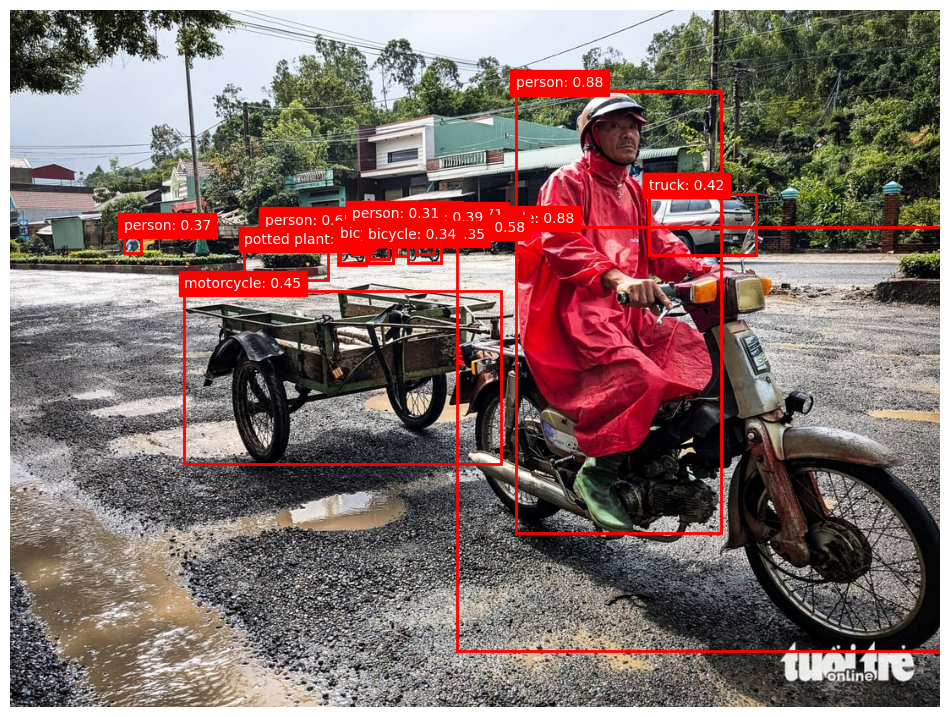

In [4]:
import os, json, torch, numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from transformers import DeformableDetrImageProcessor, DeformableDetrForObjectDetection
import requests
from io import BytesIO

BEST_MODEL_DIR = "/kaggle/working/best_model"
CHECKPOINT_FILE = "/kaggle/working/detr_resume_checkpoint.pth"
FALLBACK_MODEL = "SenseTime/deformable-detr"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_model_and_processor():
    if os.path.isdir(BEST_MODEL_DIR):
        print("✔ Loading from BEST_MODEL_DIR")
        processor = DeformableDetrImageProcessor.from_pretrained(BEST_MODEL_DIR)
        model = DeformableDetrForObjectDetection.from_pretrained(BEST_MODEL_DIR).to(DEVICE)
        return processor, model

    if os.path.exists(CHECKPOINT_FILE):
        print("✔ Loading checkpoint fallback")
        processor = DeformableDetrImageProcessor.from_pretrained(FALLBACK_MODEL)
        model = DeformableDetrForObjectDetection.from_pretrained(FALLBACK_MODEL, ignore_mismatched_sizes=True)
        ckpt = torch.load(CHECKPOINT_FILE, map_location="cpu")
        model.load_state_dict(ckpt['model'], strict=False)
        return processor, model.to(DEVICE)

    print("⚠ No saved model found → using base model")
    processor = DeformableDetrImageProcessor.from_pretrained(FALLBACK_MODEL)
    model = DeformableDetrForObjectDetection.from_pretrained(FALLBACK_MODEL).to(DEVICE)
    return processor, model


processor, model = load_model_and_processor()
id2label = {int(k): v for k, v in model.config.id2label.items()}


# =============================
# ✅ Tải ảnh từ URL
# =============================
def load_image_from_url(url):
    response = requests.get(url)
    img = Image.open(BytesIO(response.content)).convert("RGB")
    return img


# =============================
# 🔥 Predict (path hoặc URL)
# =============================
def predict_and_visualize(image_input, threshold=0.3):
    if image_input.startswith("http://") or image_input.startswith("https://"):
        image = load_image_from_url(image_input)
    else:
        image = Image.open(image_input).convert("RGB")

    inputs = processor(images=image, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)

    target_sizes = torch.tensor([image.size[::-1]], device=DEVICE)
    results = processor.post_process_object_detection(outputs, target_sizes=target_sizes, threshold=threshold)[0]

    boxes, scores, labels = results["boxes"], results["scores"], results["labels"]

    fig, ax = plt.subplots(1, figsize=(12, 12))
    ax.imshow(image)

    for box, score, lab in zip(boxes, scores, labels):
        x1, y1, x2, y2 = box.cpu().numpy()
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                 linewidth=2, edgecolor="red", facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, y1-5, f"{id2label[int(lab)]}: {score:.2f}",
                color="white", backgroundcolor="red", fontsize=10)

    plt.axis("off")
    plt.show()


# =============================
# 🔥 Test ảnh từ URL
# =============================
test_url = "https://vstatic.vietnam.vn/vietnam/resource/IMAGE/2025/11/24/1763968198546_base64-176396310059133591387.jpeg"
predict_and_visualize(test_url)


In [6]:
import cv2
import torch
import numpy as np

def predict_video_fast(video_path, processor, model,
                       threshold=0.3,
                       resize_factor=0.5,
                       save_output=True):

    cap = cv2.VideoCapture(video_path)

    # Lấy thông tin video gốc
    orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    # Resize nhỏ lại
    new_w = int(orig_w * resize_factor)
    new_h = int(orig_h * resize_factor)

    if save_output:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        out = cv2.VideoWriter(
            "output_fast.mp4",
            fourcc,
            fps,
            (new_w, new_h)
        )

    print("🚀 START PREDICTING VIDEO (FAST MODE)...")
    frame_idx = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Resize nhỏ → tăng tốc 2–4 lần
        frame = cv2.resize(frame, (new_w, new_h))

        # BGR → RGB
        rgb = frame[:, :, ::-1]

        # Dùng numpy trực tiếp, KHÔNG dùng PIL (nhanh hơn rất nhiều)
        inputs = processor(images=rgb, return_tensors="pt").to(DEVICE)

        with torch.no_grad():
            outputs = model(**inputs)

        target_sizes = torch.tensor([[new_h, new_w]], device=DEVICE)
        results = processor.post_process_object_detection(
            outputs, target_sizes=target_sizes, threshold=threshold
        )[0]

        boxes = results["boxes"].cpu().numpy().astype(int)
        scores = results["scores"].cpu().numpy()
        labels = results["labels"].cpu().numpy()

        # Vẽ bounding box
        for (x1, y1, x2, y2), score, lab in zip(boxes, scores, labels):
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(frame, f"{id2label[int(lab)]}: {score:.2f}",
                        (x1, max(0, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6, (0, 0, 255), 2)

        if save_output:
            out.write(frame)

        frame_idx += 1

    cap.release()
    if save_output:
        out.release()

    print("🎉 Done! Saved → output_fast.mp4")


In [ ]:
video_path = "/kaggle/input/videotest1/videoplayback (1).mp4"

predict_video_fast(
    video_path,
    processor, model,
    threshold=0.3,
    resize_factor=0.5,   # giảm size 50% cho nhanh
    save_output=True
)


🚀 START PREDICTING VIDEO (FAST MODE)...
